## Protocolo (no se modifica)
- Dataset: Predict Students' Dropout and Academic Success (UCI). Target: `Target`.
- Predicción tras el 1.er semestre. Excluidas: columnas del 2.º semestre, `Debtor` y `Tuition fees up to date`.
- Partición: 80/20 estratificada, `random_state=42`, igual que el Ejercicio 01.
- Clase prioritaria: **Dropout** (el error más costoso es no detectar un abandono).
- Métrica principal: F1 macro, con el recall de Dropout como criterio de desempate.
- El conjunto de prueba no se usa hasta el cierre; la comparación se hace con validación cruzada sobre entrenamiento.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("../data/raw/dataset.csv")
df.columns = df.columns.str.strip()

TARGET = "Target"
DROP_COLUMNS = [
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Debtor",
    "Tuition fees up to date",
]
X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.20, random_state=42, stratify=y)

cat_cols = [c for c in [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
] if c in X.columns]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Xt = preprocess.fit_transform(Xtr)
print(Xt.shape, Xt.dtype, round(Xt.nbytes / 1e6, 2), "MB")

(3539, 228) float64 6.46 MB


In [8]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

models = {
    "logistic": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000))]),
    "svm_c1":   Pipeline([("prep", preprocess), ("model", SVC(C=1, random_state=42))]),
    "svm_c10":  Pipeline([("prep", preprocess), ("model", SVC(C=10, random_state=42))]),
    "rf_100":   Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1))]),
    "rf_300":   Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1))]),
    "boost":    Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(max_depth=6, random_state=42))]),
}
print(list(models))

['logistic', 'svm_c1', 'svm_c10', 'rf_100', 'rf_300', 'boost']


In [10]:
from time import perf_counter
from pathlib import Path
import joblib, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score

# Validación interna: el test (Xte, yte) se reserva para el cierre
Xfit, Xval, yfit, yval = train_test_split(Xtr, ytr, test_size=.25, random_state=42, stratify=ytr)

MODELS_DIR = Path("../reports/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for name, model in models.items():
    fit_times = []
    for _ in range(3):
        start = perf_counter(); model.fit(Xfit, yfit)
        fit_times.append(perf_counter() - start)

    pred_times = []
    for _ in range(5):
        start = perf_counter(); pred = model.predict(Xval)
        pred_times.append((perf_counter() - start) * 1000)

    path = MODELS_DIR / f"{name}.joblib"
    joblib.dump(model, path)
    rows.append({
        "model": name,
        "f1_macro": f1_score(yval, pred, average="macro"),
        "recall_macro": recall_score(yval, pred, average="macro"),
        "recall_dropout": recall_score(yval, pred, labels=["Dropout"], average="macro"),
        "fit_median_s": np.median(fit_times),
        "predict_median_ms": np.median(pred_times),
        "size_kb": path.stat().st_size / 1024,
    })

results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False)
results

,model,f1_macro,recall_macro,recall_dropout,fit_median_s,predict_median_ms,size_kb
0,logistic,0.651913,0.645503,0.746479,0.164667,9.3436,12.329102
5,boost,0.638146,0.632257,0.693662,2.301400,18.0588,796.618164
2,svm_c10,0.634576,0.627738,0.665493,0.664424,277.1016,3182.301758
1,svm_c1,0.607628,0.602984,0.672535,0.625262,260.8295,2961.395508
4,rf_300,0.517568,0.566742,0.750000,0.623600,81.5357,5192.431641
3,rf_100,0.516037,0.561547,0.739437,0.255574,51.3258,1733.462891


In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

svm_pca = Pipeline([
 ("scale",StandardScaler()),
 ("pca",PCA(n_components=.95,random_state=42)),
 ("model",SVC(C=1,probability=True,random_state=42))
])
svm_pca.fit(Xtr,ytr)
print("Componentes:",svm_pca.named_steps["pca"].n_components_)

c:\Users\Oliver JR\Documents\SRC\notebooks\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Componentes: 22


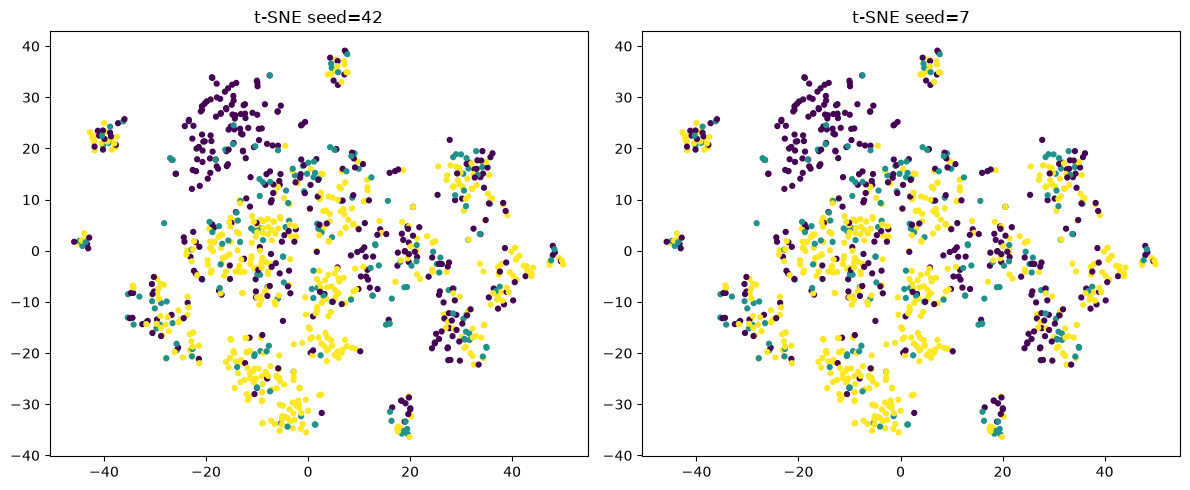

In [12]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

X_num=X.select_dtypes(include="number").fillna(X.select_dtypes(include="number").median())
sample=X_num.sample(min(1000,len(X_num)),random_state=42)
y_sample=y.loc[sample.index]
scaled=StandardScaler().fit_transform(sample)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,seed in zip(axes,[42,7]):
    emb=TSNE(n_components=2,perplexity=30,random_state=seed,init="pca",learning_rate="auto").fit_transform(scaled)
    ax.scatter(emb[:,0],emb[:,1],c=pd.Categorical(y_sample).codes,s=12,cmap="viridis")
    ax.set_title(f"t-SNE seed={seed}")
plt.tight_layout();plt.savefig("reports/tsne_two_seeds.png",dpi=160)

In [13]:
def pareto_flags(df,score="f1_macro",cost="fit_median_s"):
    flags=[]
    for _,row in df.iterrows():
        dominated=((df[score]>=row[score])&(df[cost]<=row[cost])&
          ((df[score]>row[score])|(df[cost]<row[cost]))).any()
        flags.append(not bool(dominated))
    return flags

results["is_pareto"]=pareto_flags(results)
results.to_csv("reports/green_ai_results.csv",index=False)
results.sort_values(["is_pareto","f1_macro"],ascending=[False,False])

,model,f1_macro,recall_macro,recall_dropout,fit_median_s,predict_median_ms,size_kb,is_pareto
0,logistic,0.651913,0.645503,0.746479,0.164667,9.3436,12.329102,True
5,boost,0.638146,0.632257,0.693662,2.301400,18.0588,796.618164,False
2,svm_c10,0.634576,0.627738,0.665493,0.664424,277.1016,3182.301758,False
1,svm_c1,0.607628,0.602984,0.672535,0.625262,260.8295,2961.395508,False
4,rf_300,0.517568,0.566742,0.750000,0.623600,81.5357,5192.431641,False
3,rf_100,0.516037,0.561547,0.739437,0.255574,51.3258,1733.462891,False


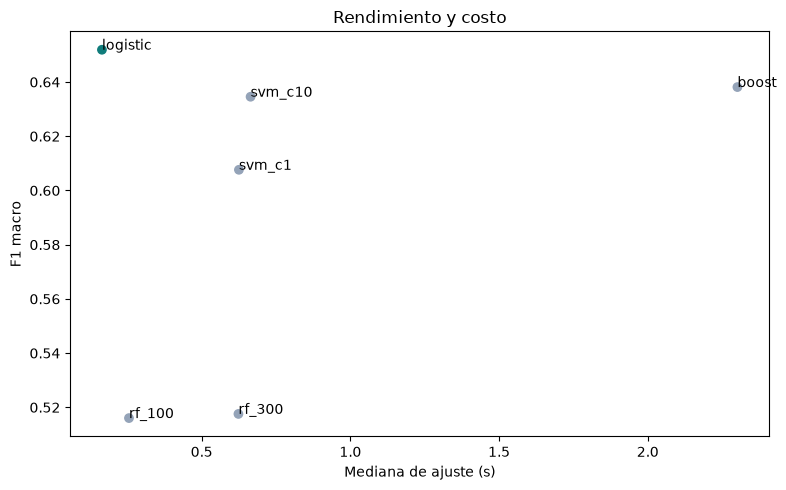

In [14]:
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(results.fit_median_s,results.f1_macro,c=results.is_pareto.map({True:"#0f7c7b",False:"#94a3b8"}))
for _,r in results.iterrows(): ax.annotate(r.model,(r.fit_median_s,r.f1_macro))
ax.set(xlabel="Mediana de ajuste (s)",ylabel="F1 macro",title="Rendimiento y costo")
plt.tight_layout();plt.savefig("reports/pareto.png",dpi=160)

In [16]:
import pandas as pd
from inf8239_u01.green import pareto_flags

def test_pareto_marks_dominated_rows():
    df=pd.DataFrame({"f1_macro":[.90,.90,.88],"fit_median_s":[2.,1.,3.]})
    assert pareto_flags(df)==[False,True,False]

def test_single_model_is_pareto():
    df=pd.DataFrame({"f1_macro":[.8],"fit_median_s":[1.]})
    assert pareto_flags(df)==[True]

ModuleNotFoundError: No module named 'inf8239_u01'

In [17]:
import platform,sys,sklearn
print("Python",sys.version)
print("Sistema",platform.platform())
print("Procesador",platform.processor())
print("scikit-learn",sklearn.__version__)

Python 3.13.13 | packaged by Anaconda, Inc. | (main, Apr 14 2026, 06:12:50) [MSC v.1942 64 bit (AMD64)]
Sistema Windows-11-10.0.26300-SP0
Procesador AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD
scikit-learn 1.9.1
